# Notebook 02: Huis Data Exploratie 

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path.cwd().parent / "locatie_data"

In [2]:
df_huis = pd.read_parquet(
    DATA_DIR / "huis788.parquet"
)

In [3]:
df_huis.head()

,timestamp,CO2,CTYPE,ENAME,ENE,ETYPE,POW,source_zip,source_csv,source_folder,...,ENE_CNT_IMP,ENE_IMP,CO2_EXP,ENE_CNT_EXP,ENE_EXP,CO2EQ,ESTYPE,forecast.ENE,forecast.POW,PRICE
0,2024-03-08 01:00:00+01:00,NaN,electricity,boiler-16eda211b788,NaN,boiler,6.504839,240308_boiler-16eda211b788_7813337caa64460dd37...,240308_boiler-16eda211b788_7813337caa64460dd37...,boiler-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-03-08 01:00:00+01:00,NaN,electricity,hoofdmeter-16eda211b788,NaN,powermeter,97.580645,240308_hoofdmeter-16eda211b788_583371188e6bd6b...,240308_hoofdmeter-16eda211b788_583371188e6bd6b...,hoofdmeter-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-03-08 01:00:00+01:00,NaN,electricity,overig-16eda211b788,NaN,powermeter,34.007143,240308_overig-16eda211b788_c9a2174e7ac825737c3...,240308_overig-16eda211b788_c9a2174e7ac825737c3...,overig-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-03-08 01:00:00+01:00,NaN,electricity,totaalverbruik-16eda211b788,NaN,powermeter,100.000000,240308_totaalverbruik-16eda211b788_15b395d52b6...,240308_totaalverbruik-16eda211b788_15b395d52b6...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-03-08 01:00:00+01:00,NaN,electricity,wcdskeukeneilandenvaatwasser-16eda211b788,NaN,dishwasher,42.476190,240308_wcdskeukeneilandenvaatwasser-16eda211b7...,240308_wcdskeukeneilandenvaatwasser-16eda211b7...,wcdskeukeneilandenvaatwasser-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Algemene controle

In [4]:
print("Shape:", df_huis.shape)
print("Chronologisch:", df_huis["timestamp"].is_monotonic_increasing)

df_huis.info()

Shape: (3057890, 22)
Chronologisch: True
<class 'pandas.DataFrame'>
RangeIndex: 3057890 entries, 0 to 3057889
Data columns (total 22 columns):
 #   Column         Dtype                           
---  ------         -----                           
 0   timestamp      datetime64[us, Europe/Amsterdam]
 1   CO2            float64                         
 2   CTYPE          str                             
 3   ENAME          str                             
 4   ENE            float64                         
 5   ETYPE          str                             
 6   POW            float64                         
 7   source_zip     str                             
 8   source_csv     str                             
 9   source_folder  str                             
 10  CO2_IMP        float64                         
 11  CTYPEC         str                             
 12  ENE_CNT_IMP    float64                         
 13  ENE_IMP        float64                         
 14  CO2_

In [5]:
#Overzicht van ontbrekende waarden voor alle kolommen
missing_overzicht = pd.DataFrame({"dtype": df_huis.dtypes.astype(str), "aantal_leeg": df_huis.isna().sum(),
                                  "percentage_leeg": (df_huis.isna().mean() * 100), "aantal_unieke_waarden": df_huis.nunique(dropna=True)})

missing_overzicht.sort_values("percentage_leeg", ascending=False)

,dtype,aantal_leeg,percentage_leeg,aantal_unieke_waarden
forecast.POW,float64,3040590,99.434250,10386
forecast.ENE,float64,3040590,99.434250,10386
ESTYPE,str,3023290,98.868501,2
CO2EQ,float64,2889822,94.503792,516
PRICE,float64,2790127,91.243537,10278
CO2_EXP,float64,2366174,77.379304,24034
CO2_IMP,float64,2349936,76.848284,42439
CO2,float64,2117250,69.238920,258959
POW,float64,1936459,63.326640,508709
ENE_CNT_IMP,float64,1934537,63.263786,601430


In [6]:
print("Missende timestamps:", df_huis["timestamp"].isna().sum())
print("Volledig dubbele rijen:", df_huis.duplicated().sum())

Missende timestamps: 0
Volledig dubbele rijen: 0


In [7]:
# Ingevulde waarden per ENAME
ingevulde_kolommen_per_ename = (df_huis.groupby("ENAME").count())

ingevulde_kolommen_per_ename

,timestamp,CO2,CTYPE,ENE,ETYPE,POW,source_zip,source_csv,source_folder,CO2_IMP,...,ENE_CNT_IMP,ENE_IMP,CO2_EXP,ENE_CNT_EXP,ENE_EXP,CO2EQ,ESTYPE,forecast.ENE,forecast.POW,PRICE
ENAME,,,,,,,,,,,,,,,,,,,,,
boiler-16eda211b788,362465,125572,362465,192339,362465,135114,362465,362465,362465,102229,...,165321,165282,102171,165264,165224,0,0,0,0,0
co2ele_combined,168068,0,168068,0,168068,0,168068,168068,168068,0,...,0,0,0,0,0,168068,0,0,0,0
forec-omvormer-16eda211b788,17300,0,17300,0,17300,0,17300,17300,17300,0,...,0,0,0,0,0,0,17300,8650,8650,0
forec-totaalverbruik-16eda211b788,17300,0,17300,0,17300,0,17300,17300,17300,0,...,0,0,0,0,0,0,17300,8650,8650,0
hoofdmeter-16eda211b788,318076,121086,318076,186724,318076,173032,318076,318076,318076,90335,...,127181,145459,74281,128631,130837,0,0,0,0,0
odectprice_c911efafaa,95109,0,95109,0,95109,0,95109,95109,95109,0,...,0,0,0,0,0,0,0,0,0,95109
omvormer-16eda211b788,368720,131025,368720,199937,368720,143660,368720,368720,368720,104250,...,167343,167299,104353,167444,167402,0,0,0,0,0
overig-16eda211b788,398790,155164,398790,228248,398790,220575,398790,398790,398790,102230,...,165321,165283,102229,165321,165282,0,0,0,0,0
priceele_123456,1437,0,1437,0,1437,0,1437,1437,1437,0,...,0,0,0,0,0,0,0,0,0,1437


### Overzicht van de meetreeksen

In [8]:
# maakt per ENAME een samenvatting vd timestamps 
overzicht = (df_huis.groupby("ENAME").agg(
        aantal_rijen=("timestamp", "size"), # telt hoeveel rijen er per ENAME zijn 
        unieke_timestamps=("timestamp", "nunique"), # telt hoeveel verschillende timestamps er per ENAME zijn 
        eerste_meting=("timestamp", "min"), # eerste timestamp die voorkomt per ENAME 
        laatste_meting=("timestamp", "max") # laatste timestamp die voorkomt per ENAME
    )
)

# berekent hoeveel extra rijen er zijn doordat timestamps vaker dan 1 keer voorkomen 
overzicht["dubbele_timestamps"] = (overzicht["aantal_rijen"] - overzicht["unieke_timestamps"])

overzicht.sort_values("aantal_rijen", ascending=False)

,aantal_rijen,unieke_timestamps,eerste_meting,laatste_meting,dubbele_timestamps
ENAME,,,,,
overig-16eda211b788,398790,230149,2024-03-08 01:00:00+01:00,2026-09-10 01:55:00+02:00,168641
totaalverbruik-16eda211b788,397154,228499,2024-03-08 01:00:00+01:00,2026-09-10 01:55:00+02:00,168655
wasmachine-16eda211b788,381248,214270,2024-03-08 01:05:00+01:00,2026-09-10 01:55:00+02:00,166978
omvormer-16eda211b788,368720,200703,2024-03-08 06:55:00+01:00,2026-09-10 01:55:00+02:00,168017
boiler-16eda211b788,362465,195413,2024-03-08 01:00:00+01:00,2026-09-10 01:55:00+02:00,167052
wcdskeukeneilandenvaatwasser-16eda211b788,361006,194555,2024-03-08 01:00:00+01:00,2026-09-10 01:55:00+02:00,166451
hoofdmeter-16eda211b788,318076,188249,2024-03-08 01:00:00+01:00,2026-09-07 08:05:00+02:00,129827
priceele_c911efafaa,171217,171217,2025-01-14 09:20:00+01:00,2026-09-10 01:55:00+02:00,0
co2ele_combined,168068,168059,2024-03-08 01:05:00+01:00,2026-09-10 01:55:00+02:00,9


In [9]:
#Toont combinatie van energietype, rol en apparaat
context_overzicht = (df_huis[["ENAME", "CTYPE", "CTYPEC", "ETYPE"]]
                     .drop_duplicates()
                     .sort_values(["ENAME", "CTYPE", "CTYPEC", "ETYPE"])
)

context_overzicht

,ENAME,CTYPE,CTYPEC,ETYPE
382106,boiler-16eda211b788,electricity,consumption,boiler
0,boiler-16eda211b788,electricity,NaN,boiler
6,co2ele_combined,electricity,NaN,co2equivalent
1133142,forec-omvormer-16eda211b788,electricity,generation,forecast-ele
1133143,forec-totaalverbruik-16eda211b788,electricity,consumption,forecast-ele
1,hoofdmeter-16eda211b788,electricity,supply,powermeter
382109,hoofdmeter-16eda211b788,electricity,NaN,powermeter
374658,odectprice_c911efafaa,electricity,consumption,priceproviderdynamic-forecast
421,omvormer-16eda211b788,electricity,generation,solarpanel
383613,omvormer-16eda211b788,electricity,NaN,solarpanel


In [10]:
#Centrale energiereeksen
TOTAALVERBRUIK = "totaalverbruik-16eda211b788"
OMVORMER = "omvormer-16eda211b788"
HOOFDMETER = "hoofdmeter-16eda211b788"

- Totaalverbruik: consumption (gebruik)
- Omvormer: generation (opwekking)
- Hoofdmeter: supply (netto energiestroom)

In [11]:
#Context van centrale energiereeksen
belangrijkste_context = context_overzicht[context_overzicht["ENAME"].isin([TOTAALVERBRUIK, OMVORMER, HOOFDMETER])]
belangrijkste_context

,ENAME,CTYPE,CTYPEC,ETYPE
1,hoofdmeter-16eda211b788,electricity,supply,powermeter
382109,hoofdmeter-16eda211b788,electricity,NaN,powermeter
421,omvormer-16eda211b788,electricity,generation,solarpanel
383613,omvormer-16eda211b788,electricity,NaN,solarpanel
3,totaalverbruik-16eda211b788,electricity,consumption,powermeter
382115,totaalverbruik-16eda211b788,electricity,NaN,powermeter


### Totaalverbruik bekijken

In [12]:
# aparte dataframe met alleen de rijen van totaalverbruik
df_totaal = (df_huis[df_huis["ENAME"] == TOTAALVERBRUIK].copy()
             .sort_values("timestamp").reset_index(drop=True)
)

print("Aantal rijen:", len(df_totaal))
print("Unieke timestamps:", df_totaal["timestamp"].nunique())

# berekent hoeveel extra rijen er zijn doordat timestamps vaker voorkomen
print("Dubbele timestamps:",
    len(df_totaal) - df_totaal["timestamp"].nunique()
)

df_totaal.head()

Aantal rijen: 397154
Unieke timestamps: 228499
Dubbele timestamps: 168655


,timestamp,CO2,CTYPE,ENAME,ENE,ETYPE,POW,source_zip,source_csv,source_folder,...,ENE_CNT_IMP,ENE_IMP,CO2_EXP,ENE_CNT_EXP,ENE_EXP,CO2EQ,ESTYPE,forecast.ENE,forecast.POW,PRICE
0,2024-03-08 01:00:00+01:00,NaN,electricity,totaalverbruik-16eda211b788,NaN,powermeter,100.0,240308_totaalverbruik-16eda211b788_15b395d52b6...,240308_totaalverbruik-16eda211b788_15b395d52b6...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-03-08 01:05:00+01:00,1.533333,electricity,totaalverbruik-16eda211b788,8.333333,powermeter,40.0,240308_totaalverbruik-16eda211b788_15b395d52b6...,240308_totaalverbruik-16eda211b788_15b395d52b6...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-03-08 01:10:00+01:00,0.613333,electricity,totaalverbruik-16eda211b788,3.333333,powermeter,45.0,240308_totaalverbruik-16eda211b788_15b395d52b6...,240308_totaalverbruik-16eda211b788_15b395d52b6...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-03-08 01:15:00+01:00,0.690000,electricity,totaalverbruik-16eda211b788,3.750000,powermeter,NaN,240308_totaalverbruik-16eda211b788_15b395d52b6...,240308_totaalverbruik-16eda211b788_15b395d52b6...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-03-08 01:20:00+01:00,NaN,electricity,totaalverbruik-16eda211b788,NaN,powermeter,45.0,240308_totaalverbruik-16eda211b788_15b395d52b6...,240308_totaalverbruik-16eda211b788_15b395d52b6...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
#Controleer in welke contexten totaalverbruik voorkomt en waar POW is gevuld.
target_context_overzicht = (df_totaal.groupby(["CTYPE", "CTYPEC", "ETYPE"],dropna=False)
    .agg(
        aantal_rijen=("timestamp", "size"),
        aantal_pow=("POW", "count"),
        eerste_meting=("timestamp", "min"),
        laatste_meting=("timestamp", "max")
    )
    .reset_index()
)

target_context_overzicht

,CTYPE,CTYPEC,ETYPE,aantal_rijen,aantal_pow,eerste_meting,laatste_meting
0,electricity,consumption,powermeter,228500,206304,2024-03-08 01:00:00+01:00,2026-09-10 01:55:00+02:00
1,electricity,NaN,powermeter,168654,0,2025-01-23 00:05:00+01:00,2026-09-10 01:55:00+02:00


In [14]:
df_dubbel = (df_totaal[df_totaal["timestamp"].duplicated(keep=False)].sort_values("timestamp"))

df_dubbel

,timestamp,CO2,CTYPE,ENAME,ENE,ETYPE,POW,source_zip,source_csv,source_folder,...,ENE_CNT_IMP,ENE_IMP,CO2_EXP,ENE_CNT_EXP,ENE_EXP,CO2EQ,ESTYPE,forecast.ENE,forecast.POW,PRICE
36129,2024-10-05 20:10:00+02:00,7.140,electricity,totaalverbruik-16eda211b788,NaN,powermeter,103.5,241005_totaalverbruik-16eda211b788_c608774f559...,241005_totaalverbruik-16eda211b788_c608774f559...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
36130,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-16eda211b788,15.0,powermeter,180.0,241005_totaalverbruik-16eda211b788_c608774f559...,241005_totaalverbruik-16eda211b788_c608774f559...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
59767,2025-01-23 00:05:00+01:00,NaN,electricity,totaalverbruik-16eda211b788,NaN,powermeter,NaN,250122_totaalverbruik-16eda211b788_661c17963b3...,250122_totaalverbruik-16eda211b788_661c17963b3...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
59768,2025-01-23 00:05:00+01:00,6.357,electricity,totaalverbruik-16eda211b788,13.0,powermeter,160.0,250122_totaalverbruik-16eda211b788_661c17963b3...,250122_totaalverbruik-16eda211b788_661c17963b3...,totaalverbruik-16eda211b788,...,-1393390.0,13.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
59769,2025-01-23 00:10:00+01:00,NaN,electricity,totaalverbruik-16eda211b788,NaN,powermeter,NaN,250122_totaalverbruik-16eda211b788_661c17963b3...,250122_totaalverbruik-16eda211b788_661c17963b3...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
397149,2026-09-10 01:45:00+02:00,NaN,electricity,totaalverbruik-16eda211b788,NaN,powermeter,NaN,260909_totaalverbruik-16eda211b788_3f0b9a87181...,260909_totaalverbruik-16eda211b788_3f0b9a87181...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
397150,2026-09-10 01:50:00+02:00,0.000,electricity,totaalverbruik-16eda211b788,0.0,powermeter,NaN,260909_totaalverbruik-16eda211b788_3f0b9a87181...,260909_totaalverbruik-16eda211b788_3f0b9a87181...,totaalverbruik-16eda211b788,...,6327167.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
397151,2026-09-10 01:50:00+02:00,NaN,electricity,totaalverbruik-16eda211b788,NaN,powermeter,NaN,260909_totaalverbruik-16eda211b788_3f0b9a87181...,260909_totaalverbruik-16eda211b788_3f0b9a87181...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
397152,2026-09-10 01:55:00+02:00,0.000,electricity,totaalverbruik-16eda211b788,0.0,powermeter,610.0,260909_totaalverbruik-16eda211b788_3f0b9a87181...,260909_totaalverbruik-16eda211b788_3f0b9a87181...,totaalverbruik-16eda211b788,...,6327167.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN


In [15]:
overzicht_zip = (
    df_dubbel.groupby("source_zip")
    .agg(
        aantal_rijen=("timestamp", "size"),
        aantal_dubbele_timestamps=("timestamp", "nunique")
    )
    .sort_values("aantal_dubbele_timestamps", ascending=False)
)

overzicht_zip

,aantal_rijen,aantal_dubbele_timestamps
source_zip,,
260909_totaalverbruik-16eda211b788_3f0b9a87181cc9fac5d4b4a88dfdcc11.zip,576,288
260908_totaalverbruik-16eda211b788_deabbfbe703daf35e823391a46e0ddc8.zip,576,288
260907_totaalverbruik-16eda211b788_e11aea09fd66d5b7759dc4da836dff9a.zip,576,288
250123_totaalverbruik-16eda211b788_495acf74481541dc16c66c9797579c40.zip,576,288
250124_totaalverbruik-16eda211b788_267d2d3436ced46e7f996ac4f4d345a4.zip,576,288
...,...,...
260410_totaalverbruik-16eda211b788_6d2e4b2a063ac81ccfd1757c33f9a839.zip,314,157
260413_totaalverbruik-16eda211b788_46f31753cf7a736d6fbad60a0ea19948.zip,262,131
260421_totaalverbruik-16eda211b788_75646e7150cac66b12734f1759ce8e7e.zip,94,47


### POW bekijken 

In [16]:
df_totaal[["timestamp", "POW"]].head()

,timestamp,POW
0,2024-03-08 01:00:00+01:00,100.0
1,2024-03-08 01:05:00+01:00,40.0
2,2024-03-08 01:10:00+01:00,45.0
3,2024-03-08 01:15:00+01:00,NaN
4,2024-03-08 01:20:00+01:00,45.0


In [17]:
print("Ontbrekende POW:", df_totaal["POW"].isna().sum())

Ontbrekende POW: 190850


In [18]:
df_totaal['POW'].describe().T

count    206304.000000
mean        697.976404
std         770.692129
min       -2207.500000
25%         104.000000
50%         406.577731
75%        1059.746822
max        7255.975806
Name: POW, dtype: float64

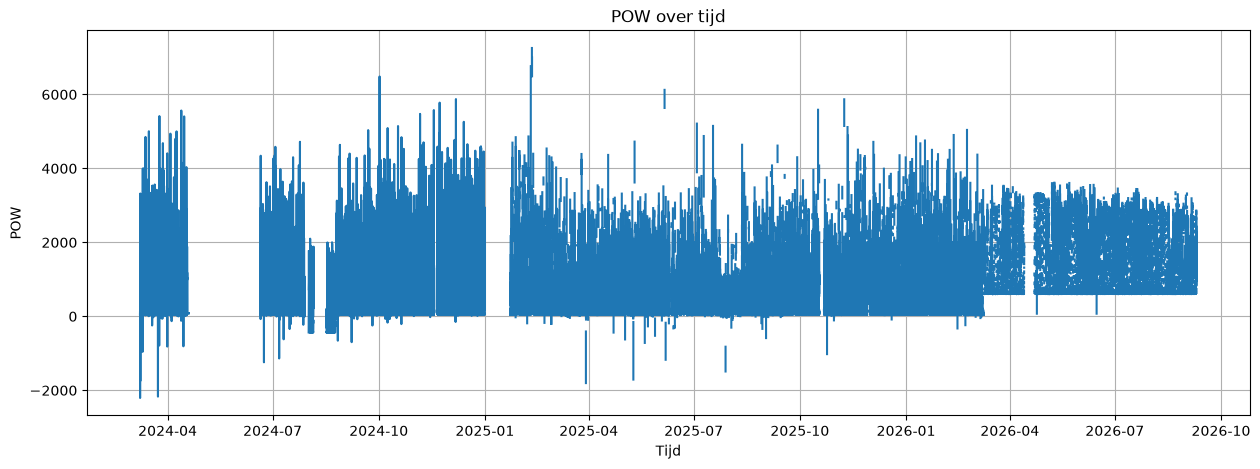

In [19]:
# POW plotten tegenover tijd
plt.figure(figsize=(15, 5))
plt.plot(df_totaal["timestamp"], df_totaal["POW"])

plt.xlabel("Tijd")
plt.ylabel("POW")
plt.title("POW over tijd")
plt.grid()
plt.show()

In [20]:
print("Eerste timestamp:", df_totaal["timestamp"].min())
print("Laatste timestamp:", df_totaal["timestamp"].max())

print(
    "Laatste timestamp met geldige POW:",
    df_totaal.loc[df_totaal["POW"].notna(), "timestamp"].max()
)

Eerste timestamp: 2024-03-08 01:00:00+01:00
Laatste timestamp: 2026-09-10 01:55:00+02:00
Laatste timestamp met geldige POW: 2026-09-10 01:55:00+02:00


### Dubbele pow op zelfde CTYPE, CTYPEC, ENAME en ETYPE (over alle records)

In [21]:
#Alleen rijen waar POW aanwezig is
df_pow = df_huis[df_huis["POW"].notna()].copy()

#Zoektype van Pieter
filter = ["timestamp", "CTYPE", "CTYPEC", "ENAME", "ETYPE"]

dubbel = df_pow.duplicated(subset=filter,keep=False)

dubbele_pow = (df_pow.loc[dubbel].sort_values(filter))

dubbele_pow

,timestamp,CO2,CTYPE,ENAME,ENE,ETYPE,POW,source_zip,source_csv,source_folder,...,ENE_CNT_IMP,ENE_IMP,CO2_EXP,ENE_CNT_EXP,ENE_EXP,CO2EQ,ESTYPE,forecast.ENE,forecast.POW,PRICE
224530,2024-10-05 20:10:00+02:00,7.140000,electricity,totaalverbruik-16eda211b788,NaN,powermeter,103.500000,241005_totaalverbruik-16eda211b788_c608774f559...,241005_totaalverbruik-16eda211b788_c608774f559...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
224531,2024-10-05 20:10:00+02:00,NaN,electricity,totaalverbruik-16eda211b788,15.000000,powermeter,180.000000,241005_totaalverbruik-16eda211b788_c608774f559...,241005_totaalverbruik-16eda211b788_c608774f559...,totaalverbruik-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
224525,2024-10-05 20:10:00+02:00,5.910333,electricity,hoofdmeter-16eda211b788,NaN,powermeter,112.941176,241005_hoofdmeter-16eda211b788_8f02b76d3db5193...,241005_hoofdmeter-16eda211b788_8f02b76d3db5193...,hoofdmeter-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
224526,2024-10-05 20:10:00+02:00,NaN,electricity,hoofdmeter-16eda211b788,12.416667,powermeter,181.666667,241005_hoofdmeter-16eda211b788_8f02b76d3db5193...,241005_hoofdmeter-16eda211b788_8f02b76d3db5193...,hoofdmeter-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
224521,2024-10-05 20:10:00+02:00,0.180849,electricity,boiler-16eda211b788,NaN,boiler,46.356818,241005_boiler-16eda211b788_e14afb7f21159dfdee2...,241005_boiler-16eda211b788_e14afb7f21159dfdee2...,boiler-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
224522,2024-10-05 20:10:00+02:00,NaN,electricity,boiler-16eda211b788,0.379934,boiler,4.550000,241005_boiler-16eda211b788_e14afb7f21159dfdee2...,241005_boiler-16eda211b788_e14afb7f21159dfdee2...,boiler-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
224528,2024-10-05 20:10:00+02:00,2.479769,electricity,overig-16eda211b788,NaN,powermeter,59.041071,241005_overig-16eda211b788_2058e3ce58a10957a48...,241005_overig-16eda211b788_2058e3ce58a10957a48...,overig-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
224529,2024-10-05 20:10:00+02:00,NaN,electricity,overig-16eda211b788,5.209599,powermeter,63.043478,241005_overig-16eda211b788_2058e3ce58a10957a48...,241005_overig-16eda211b788_2058e3ce58a10957a48...,overig-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
224532,2024-10-05 20:10:00+02:00,1.167115,electricity,wasmachine-16eda211b788,NaN,washingmachine,41.000000,241005_wasmachine-16eda211b788_57f80165066537e...,241005_wasmachine-16eda211b788_57f80165066537e...,wasmachine-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
224533,2024-10-05 20:10:00+02:00,NaN,electricity,wasmachine-16eda211b788,2.451923,washingmachine,27.500000,241005_wasmachine-16eda211b788_57f80165066537e...,241005_wasmachine-16eda211b788_57f80165066537e...,wasmachine-16eda211b788,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
#Dubbele POW op alleen ctype (energietype), ctypec (rol) en etype (apparaat)
kolommen = [
    "timestamp",
    "CTYPE",
    "CTYPEC",
    "ENAME",
    "ETYPE",
    "POW"
]

dubbele_pow[kolommen].head(50)

,timestamp,CTYPE,CTYPEC,ENAME,ETYPE,POW
224530,2024-10-05 20:10:00+02:00,electricity,consumption,totaalverbruik-16eda211b788,powermeter,103.500000
224531,2024-10-05 20:10:00+02:00,electricity,consumption,totaalverbruik-16eda211b788,powermeter,180.000000
224525,2024-10-05 20:10:00+02:00,electricity,supply,hoofdmeter-16eda211b788,powermeter,112.941176
224526,2024-10-05 20:10:00+02:00,electricity,supply,hoofdmeter-16eda211b788,powermeter,181.666667
224521,2024-10-05 20:10:00+02:00,electricity,NaN,boiler-16eda211b788,boiler,46.356818
224522,2024-10-05 20:10:00+02:00,electricity,NaN,boiler-16eda211b788,boiler,4.550000
224528,2024-10-05 20:10:00+02:00,electricity,NaN,overig-16eda211b788,powermeter,59.041071
224529,2024-10-05 20:10:00+02:00,electricity,NaN,overig-16eda211b788,powermeter,63.043478
224532,2024-10-05 20:10:00+02:00,electricity,NaN,wasmachine-16eda211b788,washingmachine,41.000000
224533,2024-10-05 20:10:00+02:00,electricity,NaN,wasmachine-16eda211b788,washingmachine,27.500000


### Exacte contextdata erbij selecteren en aantal records zonder POW 
- Rijen zonder POW kunnen wél ENE of CO2 bevatten.

In [23]:
df_totaal_context = df_huis[
    (df_huis["ENAME"] == TOTAALVERBRUIK) &
    (df_huis["CTYPE"] == "electricity") &
    (df_huis["CTYPEC"] == "consumption") &
    (df_huis["ETYPE"] == "powermeter")
].copy()

geen_pow = df_totaal_context[df_totaal_context["POW"].isna()].copy()
print("Records binnen targetcontext zonder POW:", len(geen_pow))

Records binnen targetcontext zonder POW: 22196


In [24]:
#Controleer welke andere meetkolommen wél gevuld zijn zonder POW (voorkomen dat ENE records als missing POW worden geteld)
andere_kolommen = [
    "POW", "ENE", "ENE_EXP", "ENE_IMP", "ENE_CNT_EXP", "ENE_CNT_IMP", "CO2", "CO2_EXP", "CO2_IMP",
    "CO2EQ", "forecast.POW", "forecast.ENE", "PRICE"]

andere_kolommen = [kolom for kolom in andere_kolommen if kolom in geen_pow.columns]
geen_pow[andere_kolommen].notna().sum().sort_values(ascending=False).to_frame("geen POW maar wél deze waarden;")

,geen POW maar wél deze waarden;
ENE,22188
ENE_CNT_EXP,18883
ENE_CNT_IMP,18883
ENE_IMP,18876
ENE_EXP,18876
CO2,14581
CO2_EXP,11901
CO2_IMP,11901
POW,0
CO2EQ,0


### Meetfrequentie en ontbrekende timestamps
- Nominale frequentie
- Meest voorkomend: 5 minuten

In [25]:
df_pow_totaal = (df_totaal_context[df_totaal_context["POW"].notna()].copy().sort_values("timestamp").reset_index(drop=True))

#Iedere timestamp telt één keer (voor frequentie)
pow_tijden = (df_pow_totaal["timestamp"].drop_duplicates().sort_values().reset_index(drop=True))

#Meest voorkomende afstand (frequentie)
tijdverschillen = (pow_tijden.diff().value_counts().sort_values(ascending=False))
tijdverschillen.head(15).to_frame("aantal")

,aantal
timestamp,
0 days 00:05:00,187566
0 days 00:10:00,16615
0 days 00:15:00,1430
0 days 00:20:00,500
0 days 00:25:00,128
0 days 01:05:00,7
0 days 00:35:00,4
0 days 01:30:00,3
0 days 00:45:00,2


In [26]:
#5 minuten raster maken en timestamps die hierin verwacht worden maar niet voorkomen in targetreeks
verwachte_tijden = pd.date_range(start=pow_tijden.min(), end=pow_tijden.max(), freq="5min")

ontbrekende_pow_tijden = verwachte_tijden.difference(pow_tijden)
print("Ontbrekende timestamps binnen totaalgebruik:", len(ontbrekende_pow_tijden))

Ontbrekende timestamps binnen totaalgebruik: 57505


### Verdeling en spreiding POW binnen totaalgebruik

In [27]:
target_skewness = df_pow_totaal["POW"].skew()
print("Skewness:", target_skewness)
print("Negatieve POW:", (df_pow_totaal["POW"] < 0).sum())
print("POW = 0:", (df_pow_totaal["POW"] == 0).sum())
df_pow_totaal["POW"].describe().to_frame("POW")

Skewness: 1.522508657754539
Negatieve POW: 1162
POW = 0: 0


,POW
count,206304.000000
mean,697.976404
std,770.692129
min,-2207.500000
25%,104.000000
50%,406.577731
75%,1059.746822
max,7255.975806


### Grootste gaten
- Kijken naar de grootste gaten in de data
- Gaten indelen naar hoeveel punten van 5 minuten ontbreken

In [28]:
tijd_df = pd.DataFrame({"timestamp": pow_tijden})
tijd_df["vorige_timestamp"] = tijd_df["timestamp"].shift(1)
tijd_df["tijdverschil"] = (tijd_df["timestamp"] - tijd_df["vorige_timestamp"])

#Ieder tijdverschil omzetten naar aantal ontbrekende punten van 5 minuten
tijd_df["ontbrekende_punten"] = (tijd_df["tijdverschil"] / pd.Timedelta(minutes=5) - 1).clip(lower=0).round().astype("Int64")

In [29]:
#Grootste gaten
tijd_df[["vorige_timestamp", "timestamp", "tijdverschil", "ontbrekende_punten"]].sort_values("tijdverschil", ascending=False).head(15)

,vorige_timestamp,timestamp,tijdverschil,ontbrekende_punten
10488,2024-05-26 10:35:00+02:00,2024-06-20 12:15:00+02:00,25 days 01:40:00,7219
56508,2025-01-01 00:10:00+01:00,2025-01-23 00:05:00+01:00,21 days 23:55:00,6334
10486,2024-05-08 09:20:00+02:00,2024-05-24 00:50:00+02:00,15 days 15:30:00,4505
10485,2024-04-23 06:20:00+02:00,2024-05-08 09:20:00+02:00,15 days 03:00:00,4355
21722,2024-08-05 17:50:00+02:00,2024-08-16 17:30:00+02:00,10 days 23:40:00,3163
173117,2026-04-13 12:50:00+02:00,2026-04-22 06:15:00+02:00,8 days 17:25:00,2512
128035,2025-10-17 23:55:00+02:00,2025-10-21 21:25:00+02:00,3 days 21:30:00,1121
20831,2024-07-28 18:45:00+02:00,2024-08-01 05:45:00+02:00,3 days 11:00:00,995
45599,2024-11-17 23:05:00+01:00,2024-11-20 11:00:00+01:00,2 days 11:55:00,718
10487,2024-05-24 00:50:00+02:00,2024-05-26 10:35:00+02:00,2 days 09:45:00,692


In [30]:
#Gaten indelen op basis van totale duur
def categorie_gat(verschil):
    if pd.isna(verschil):
        return None
    if verschil == pd.Timedelta(minutes=5):
        return "geen gat"
    if verschil <= pd.Timedelta(minutes=15):
        return "5-10 min"
    if verschil <= pd.Timedelta(hours=1):
        return "15-55 min"
    if verschil <= pd.Timedelta(hours=6):
        return "1-6 uur"
    if verschil <= pd.Timedelta(days=1):
        return "6-24 uur"
    return "meer dan 1 dag"

In [31]:
#Toekennen (zie functie hierboven)
tijd_df["gat_categorie"] = (tijd_df["tijdverschil"].apply(categorie_gat))

#Samenvatting van aantal verschillende gaten
gat_samenvatting = (tijd_df[tijd_df["gat_categorie"] != "geen gat"].groupby("gat_categorie")
                    .agg(aantal_gaten=("tijdverschil", "size"), ontbrekende_punten=("ontbrekende_punten", "sum"))
)

In [32]:
gat_samenvatting.sort_values("ontbrekende_punten", ascending=False)

,aantal_gaten,ontbrekende_punten
gat_categorie,,
meer dan 1 dag,12,32685
5-10 min,18045,19475
6-24 uur,22,2781
15-55 min,638,2078
1-6 uur,19,486


### Visuele verdeling

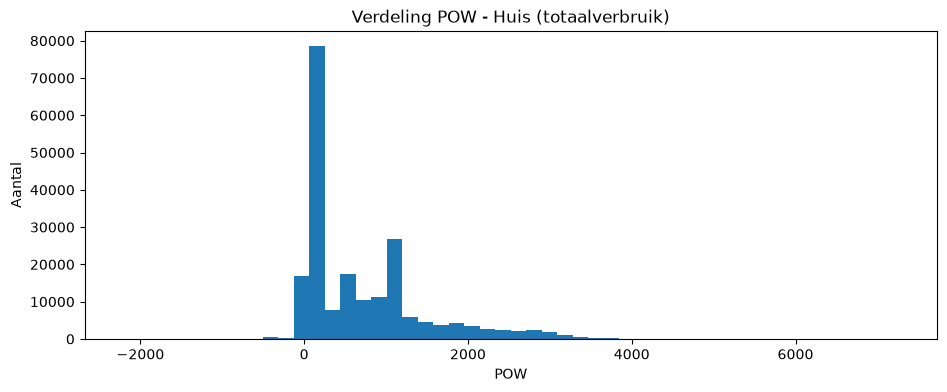

In [33]:
#Targetverdeling binnen totaalverbruik
plt.figure(figsize=(11, 4))
plt.hist(df_pow_totaal["POW"].dropna(), bins=50)
plt.xlabel("POW")
plt.ylabel("Aantal")
plt.title("Verdeling POW - Huis (totaalverbruik)")
plt.show()

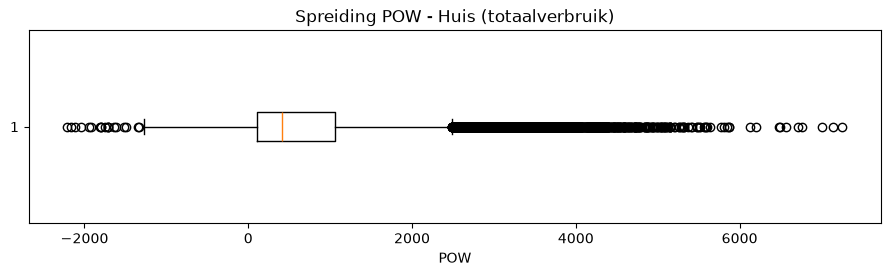

In [34]:
#Boxplot POW
plt.figure(figsize=(11, 2.5))
plt.boxplot(df_pow_totaal["POW"].dropna(), orientation="horizontal")
plt.xlabel("POW")
plt.title("Spreiding POW - Huis (totaalverbruik)")
plt.show()

### Tijdspatronen (verbruik)

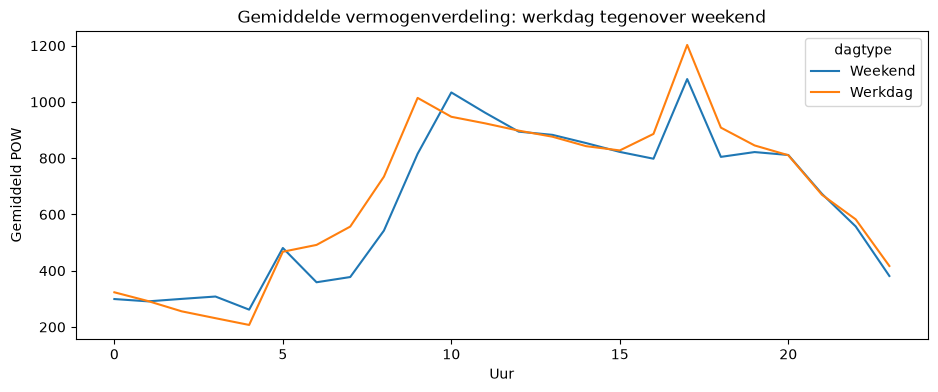

In [35]:
#Tijdvariabelen aanmaken + weekend van werkdag onderscheiden
df_target_analyse = df_pow_totaal.copy()
df_target_analyse["uur"] = df_target_analyse["timestamp"].dt.hour
df_target_analyse["weekdag"] = df_target_analyse["timestamp"].dt.dayofweek
df_target_analyse["dagtype"] = df_target_analyse["weekdag"].map(lambda x: "Weekend" if x >= 5 else "Werkdag")
df_target_analyse["jaar_maand"] = (df_target_analyse["timestamp"].dt.strftime("%Y-%m"))
dagtype_profiel = (df_target_analyse.groupby(["uur", "dagtype"])["POW"].mean().unstack())

df_target_analyse.groupby("dagtype")["POW"].agg(["count", "mean", "median", "std"])


dagtype_profiel.plot(figsize=(11, 4))
plt.xlabel("Uur")
plt.ylabel("Gemiddeld POW")
plt.title("Gemiddelde vermogenverdeling: werkdag tegenover weekend")
plt.show()

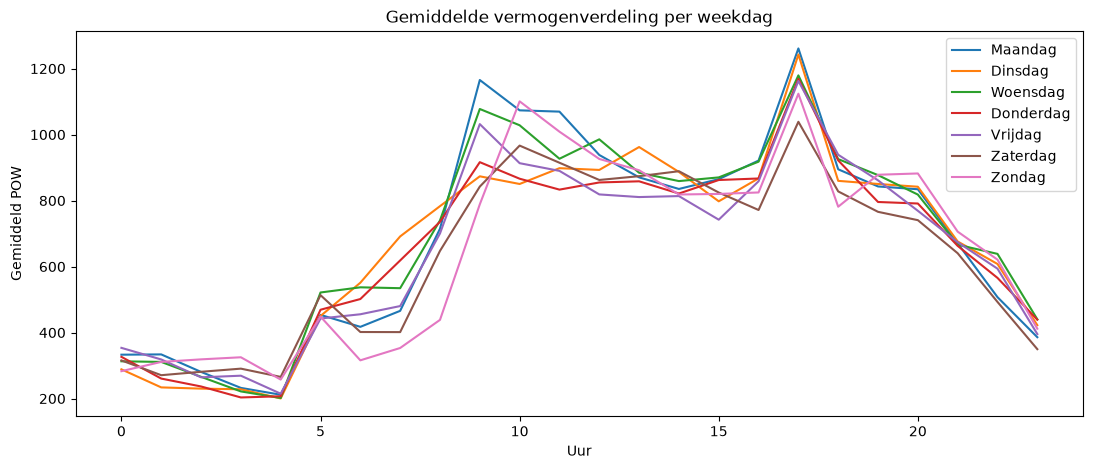

In [36]:
#Gemiddeld uurprofiel voor iedere dag
weekdag_profiel = (df_target_analyse.groupby(["uur", "weekdag"])["POW"].mean().unstack().reindex(columns=range(7)))
weekdag_profiel.columns = ["Maandag", "Dinsdag", "Woensdag","Donderdag", "Vrijdag", "Zaterdag", "Zondag"]
weekdag_profiel.plot(figsize=(13, 5))
plt.xlabel("Uur")
plt.ylabel("Gemiddeld POW")
plt.title("Gemiddelde vermogenverdeling per weekdag")
plt.show()

### Maandstatistieken

In [37]:
#Aantal, gemiddelde en mediaan van POW
maand_statistieken = (df_target_analyse.groupby("jaar_maand")["POW"].agg(aantal="count", gemiddelde="mean", mediaan="median"))
maand_statistieken

,aantal,gemiddelde,mediaan
jaar_maand,,,
2024-03,6219,542.683837,134.820000
2024-04,4266,574.722435,146.794064
2024-05,3,72.000000,72.000000
2024-06,2866,563.841004,144.444444
2024-07,7477,504.083632,148.571429
2024-08,4283,419.419956,153.333333
2024-09,7985,477.580234,144.062016
2024-10,8072,529.493522,144.064386
2024-11,7160,600.719483,168.637236


### Opwekking
- Omvormer voor huisdata
- Naast verbruik ook opwekking kunnen voorspellen

In [38]:
#Alleen echte POW metingen van omvormer selecteren op generation
df_opwekking = (df_huis[(df_huis["ENAME"] == OMVORMER) & (df_huis["CTYPEC"] == "generation") & (df_huis["POW"].notna())]
                .copy().sort_values("timestamp"))

In [39]:
#Context omvormer
df_opwekking[["CTYPE", "CTYPEC", "ETYPE"]].drop_duplicates()

,CTYPE,CTYPEC,ETYPE
421,electricity,generation,solarpanel


In [40]:
print("Aantal POW-metingen:", len(df_opwekking))
df_opwekking["POW"].describe().to_frame("POW_omvormer")

Aantal POW-metingen: 143660


,POW_omvormer
count,143660.000000
mean,-626.947187
std,740.918720
min,-3008.316327
25%,-1019.406618
50%,-298.102313
75%,-30.682192
max,7.666667


### Visualisatie: Opwekking per dag

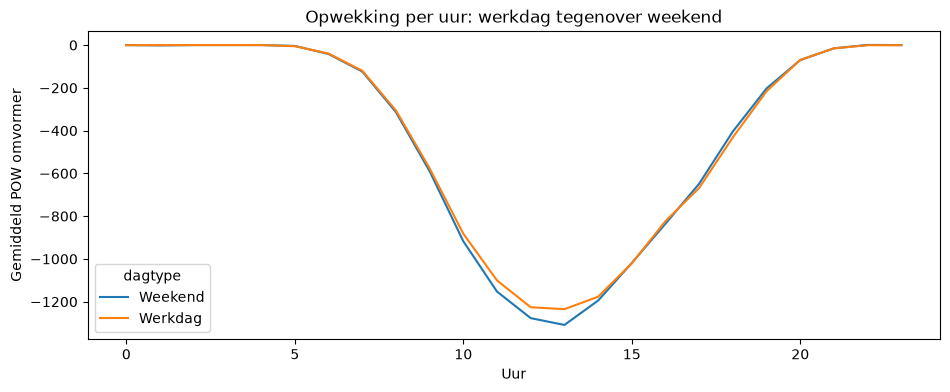

In [41]:
#Tijdvariabelen aanmaken + weekend van werkdag onderscheiden
df_opwekking["uur"] = df_opwekking["timestamp"].dt.hour
df_opwekking["weekdag"] = df_opwekking["timestamp"].dt.dayofweek
df_opwekking["dagtype"] = df_opwekking["weekdag"].map(lambda x: "Weekend" if x >= 5 else "Werkdag")
opwekking_dagtype = (df_opwekking.groupby(["uur", "dagtype"])["POW"].mean().unstack())

opwekking_dagtype.plot(figsize=(11, 4))
plt.xlabel("Uur")
plt.ylabel("Gemiddeld POW omvormer")
plt.title("Opwekking per uur: werkdag tegenover weekend")
plt.show()

### Hoofdmeter als supply reeks
- Opdrachtgever zegt dat netto energiestroom wordt gezien als CTYPEC = supply
- Kijken of totaalverbruik + omvormer ongeveer gelijk is aan de hoofdmeter supply

In [42]:
#Context selecteren van de hoofdmeter
df_hoofdmeter_supply = (df_huis[
    (df_huis["ENAME"] == HOOFDMETER) &
    (df_huis["CTYPE"] == "electricity") &
    (df_huis["CTYPEC"] == "supply") &
    (df_huis["ETYPE"] == "powermeter") &
    (df_huis["POW"].notna())
].copy().sort_values("timestamp"))

In [43]:
#Context hoofdmeter supply
df_hoofdmeter_supply[["CTYPE", "CTYPEC", "ETYPE"]].drop_duplicates()

,CTYPE,CTYPEC,ETYPE
1,electricity,supply,powermeter


In [44]:
print("Aantal POW-metingen:", len(df_hoofdmeter_supply))
df_hoofdmeter_supply["POW"].describe().to_frame("POW_hoofdmeter_supply")

Aantal POW-metingen: 173032


,POW_hoofdmeter_supply
count,173032.000000
mean,171.281502
std,887.153360
min,-2943.666667
25%,-26.666667
50%,95.666667
75%,520.666667
max,7148.000000


In [45]:
#Één POW waarde per timestamp voor zowel totaalgebruik, opwekking en hoofdmeter maken
totaal_per_tijd = (df_pow_totaal.groupby("timestamp")["POW"].mean().rename("POW_totaal"))
opwekking_per_tijd = (df_opwekking.groupby("timestamp")["POW"].mean().rename("POW_omvormer"))
hoofdmeter_per_tijd = (df_hoofdmeter_supply.groupby("timestamp")["POW"].mean().rename("POW_hoofdmeter"))

#Alleen gebruiken als ze alle 3 bschikbaar zijn
balans_check = pd.concat([totaal_per_tijd, opwekking_per_tijd, hoofdmeter_per_tijd], axis=1, join="inner").dropna()

#Balans = verbruik + opwekking
balans_check["totaal_plus_opwekking"] = (balans_check["POW_totaal"] + balans_check["POW_omvormer"])

#Afwijking
balans_check["verschil_met_hoofdmeter"] = (balans_check["POW_hoofdmeter"] - balans_check["totaal_plus_opwekking"])

In [46]:
print("Aantal gezamenlijke timestamps:", len(balans_check))
print("Correlatie hoofdmeter tegenover verbruik + opwekking:", balans_check["POW_hoofdmeter"].corr(balans_check["totaal_plus_opwekking"]))
print("Gemiddelde absolute afwijking (in Watt):", balans_check["verschil_met_hoofdmeter"].abs().mean())
print("Mediaan afwijking (in Watt):", balans_check["verschil_met_hoofdmeter"].median())

Aantal gezamenlijke timestamps: 99323
Correlatie hoofdmeter tegenover verbruik + opwekking: 0.9987386195042243
Gemiddelde absolute afwijking (in Watt): 14.843980578772973
Mediaan afwijking (in Watt): 0.0


In [47]:
balans_check[["POW_totaal", "POW_omvormer", "totaal_plus_opwekking", "POW_hoofdmeter", "verschil_met_hoofdmeter"]].head(20)

,POW_totaal,POW_omvormer,totaal_plus_opwekking,POW_hoofdmeter,verschil_met_hoofdmeter
timestamp,,,,,
2024-03-08 06:55:00+01:00,48.538462,2.775000,51.313462,59.333333,8.019872
2024-03-08 07:00:00+01:00,981.960000,0.920000,982.880000,782.166667,-200.713333
2024-03-08 07:05:00+01:00,984.166667,-4.927848,979.238819,978.000000,-1.238819
2024-03-08 07:10:00+01:00,969.164062,-11.160504,958.003558,959.000000,0.996442
2024-03-08 07:15:00+01:00,136.415385,-17.794737,118.620648,106.000000,-12.620648
2024-03-08 07:20:00+01:00,45.573171,-28.089706,17.483465,18.666667,1.183202
2024-03-08 07:25:00+01:00,45.184615,-42.020000,3.164615,4.166667,1.002051
2024-03-08 07:30:00+01:00,70.619048,-65.530612,5.088435,5.333333,0.244898
2024-03-08 07:35:00+01:00,525.700000,-80.285714,445.414286,492.000000,46.585714


### Correlaties
- Zowel Pearson als Spearman correlatie coëfficient
- Zowel lineaire relaties als niet lineair (maar wel in één richting)

In [48]:
#Pakt alle ENAME's met bestaande POW-metingen
pow_enames = sorted(df_huis.loc[df_huis["POW"].notna(),"ENAME"].dropna().unique())
pow_wide = (df_huis[df_huis["ENAME"].isin(pow_enames) & df_huis["POW"].notna()]
            .pivot_table(index="timestamp", columns="ENAME", values="POW", aggfunc="mean"))

pearson = pow_wide.corr(method="pearson")
spearman = pow_wide.corr(method="spearman")

#Telt alle beschikbare timestamps per ENAME
valid_matrix = pow_wide.notna().astype("int64")
overlap_matrix = valid_matrix.T @ valid_matrix

#DataFrame maken gesorteerd op Pearson correlatie coëfficient aflopend (correlatie met totaalverbruik)
corr_target = pd.DataFrame({"pearson": pearson[TOTAALVERBRUIK].drop(TOTAALVERBRUIK),
                            "spearman": spearman[TOTAALVERBRUIK].drop(TOTAALVERBRUIK),
                            "gezamenlijke_timestamps": overlap_matrix[TOTAALVERBRUIK].drop(TOTAALVERBRUIK)})

corr_target = corr_target.loc[corr_target["pearson"].abs().sort_values(ascending=False).index]
corr_target

,pearson,spearman,gezamenlijke_timestamps
ENAME,,,
overig-16eda211b788,0.759908,0.610964,205164
hoofdmeter-16eda211b788,0.722893,0.664479,162980
boiler-16eda211b788,0.407744,0.470464,124198
omvormer-16eda211b788,-0.330141,-0.222159,138414
wcdskeukeneilandenvaatwasser-16eda211b788,0.291734,0.079801,104788
wasmachine-16eda211b788,0.233383,0.099981,118366


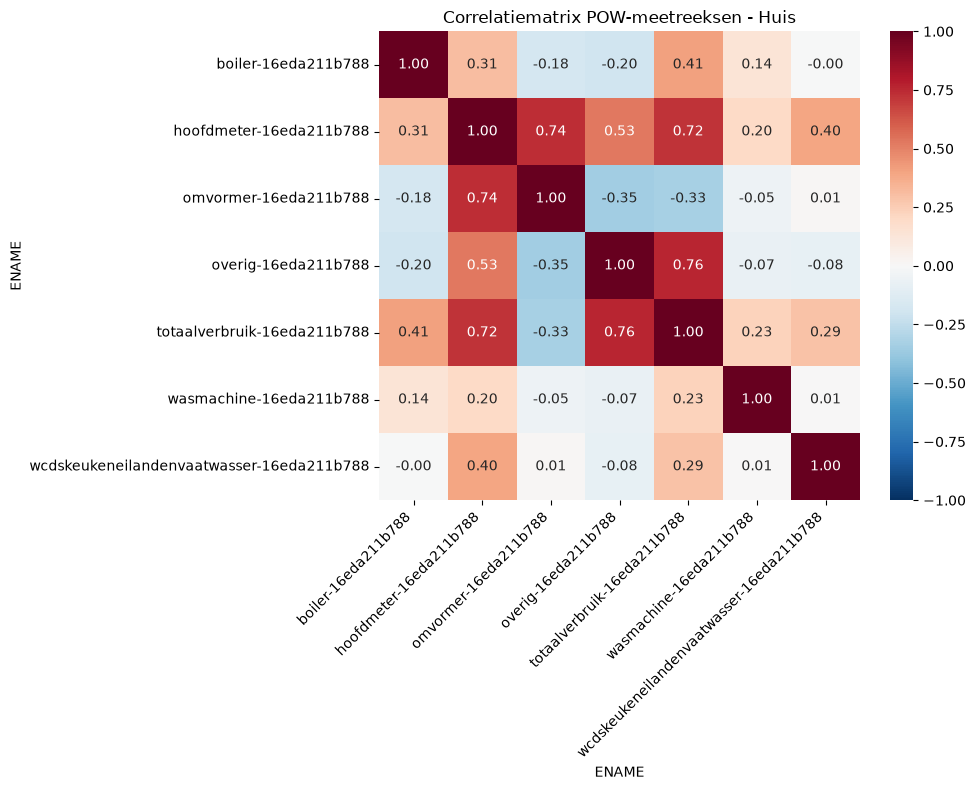

In [49]:
# Pearson-correlaties tussen de POW meetreeksen
corr_matrix = pow_wide.corr(method="pearson", min_periods=1000)

plt.figure(figsize=(10, 8))

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r",vmin=-1, vmax=1)

plt.title("Correlatiematrix POW-meetreeksen - Huis")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Lagcorrelaties
- Hoeveel hangt target samen met exact dezelfde tijd 5 minuten, 1 uur, 6 uur, 1 dag, 2 dagen, 3 dagen en 7 dagen eerder

In [50]:
#Verwijderd dubbele timestamps
target_uniek = (df_pow_totaal[~df_pow_totaal["timestamp"].duplicated(keep=False)][["timestamp", "POW"]]
                .set_index("timestamp")["POW"]
                .sort_index())

In [51]:
#Correlatie berekenen tussen POW (tijd) en POW (tijd - verschil)
def exacte_lag_correlatie(series, verschil):
    huidig = series.rename("POW_huidig").to_frame()
    verleden = series.rename("POW_verleden").copy()
    verleden.index = verleden.index + verschil
    gekoppeld = (huidig.join(verleden, how="inner").dropna())

    return pd.Series({
        "aantal_paren": len(gekoppeld),
        "correlatie": gekoppeld["POW_huidig"].corr(gekoppeld["POW_verleden"])
        })

In [52]:
lags = {
    "5 minuten": pd.Timedelta(minutes=5),
    "1 uur": pd.Timedelta(hours=1),
    "6 uur": pd.Timedelta(hours=6),
    "24 uur": pd.Timedelta(hours=24),
    "48 uur": pd.Timedelta(hours=48),
    "72 uur": pd.Timedelta(hours=72),
    "7 dagen": pd.Timedelta(days=7)
}

In [53]:
#Pearson correlatie coëfficient tussen huidige en historische POW berekenen voor iedere lag (tijdsafstand)
lag_resultaten = pd.DataFrame({naam: exacte_lag_correlatie(target_uniek, verschil) for naam, verschil in lags.items()}).T
lag_resultaten

,aantal_paren,correlatie
5 minuten,187565.0,0.868243
1 uur,194738.0,0.494304
6 uur,185931.0,0.110623
24 uur,188630.0,0.433625
48 uur,186925.0,0.422812
72 uur,185054.0,0.423563
7 dagen,180363.0,0.416540


### Interpretatie lag_resultaten
- 5 minuten heeft hoogste correlatie, daarna zakt hij en deze stijgt weer rond 1 dag
- Normale resultaten dagelijks gebruik